### Строим дерево глубиной 3, рисуем схему и матрицу ошибок, сравниваем Джини с энтропией и проверяем переобучение на глубоком дереве

In [1]:
import sys
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

sys.path.insert(0, str(Path("..").resolve()))
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import classification_report, roc_auc_score
from src.common import load_dataset, split_data, get_feature_names, evaluate, plot_tree, plot_confusion
from src.models import build_decision_tree
from src.metrics import compute_root_information_gain

df = load_dataset()
X_train, X_test, y_train, y_test = split_data(df, test_size=0.2, random_state=42)

configs = [
    ("Дерево гл. 3, Джини", dict(max_depth=3, criterion="gini", min_samples_leaf=1)),
    ("Дерево гл. 3, энтропия", dict(max_depth=3, criterion="entropy", min_samples_leaf=1)),
    ("Глубокое Джини, лист 10", dict(max_depth=None, criterion="gini", min_samples_leaf=10)),
    ("Глубокое энтропия, лист 10", dict(max_depth=None, criterion="entropy", min_samples_leaf=10)),
]

rows = []
fitted_pipes = {}
for name, kw in configs:
    pipe = build_decision_tree(**kw)
    pipe.fit(X_train, y_train)
    tr_auc = roc_auc_score(y_train, pipe.predict_proba(X_train)[:, 1])
    m = evaluate(pipe, X_test, y_test)
    ig = compute_root_information_gain(pipe.named_steps["clf"])
    rows.append({
        "Модель": name,
        "Глубина": pipe.named_steps["clf"].get_depth(),
        "Листья": pipe.named_steps["clf"].get_n_leaves(),
        "Обуч. ROC-AUC": round(tr_auc, 4),
        "Тест ROC-AUC": round(m["roc_auc"], 4),
        "Доля верных": round(m["accuracy"], 4),
        "Точность": round(m["precision"], 4),
        "Полнота": round(m["recall"], 4),
        "F1": round(m["f1"], 4),
        "G-среднее": round(m["gmean"], 4),
        "Прирост корня": round(ig, 4),
    })
    fitted_pipes[name] = pipe

comp_df = pd.DataFrame(rows)
display(comp_df)

,Модель,Глубина,Листья,Обуч. ROC-AUC,Тест ROC-AUC,Доля верных,Точность,Полнота,F1,G-среднее,Прирост корня
0,"Дерево гл. 3, Джини",3,8,0.8411,0.8335,0.7699,0.3095,0.7854,0.4440,0.7766,0.1005
1,"Дерево гл. 3, энтропия",3,8,0.8373,0.8273,0.7699,0.3095,0.7854,0.4440,0.7766,0.1504
2,"Глубокое Джини, лист 10",25,1058,0.9705,0.8669,0.8504,0.4260,0.8025,0.5565,0.8292,0.1005
3,"Глубокое энтропия, лист 10",26,1069,0.9714,0.8496,0.8403,0.4041,0.7684,0.5296,0.8081,0.1504


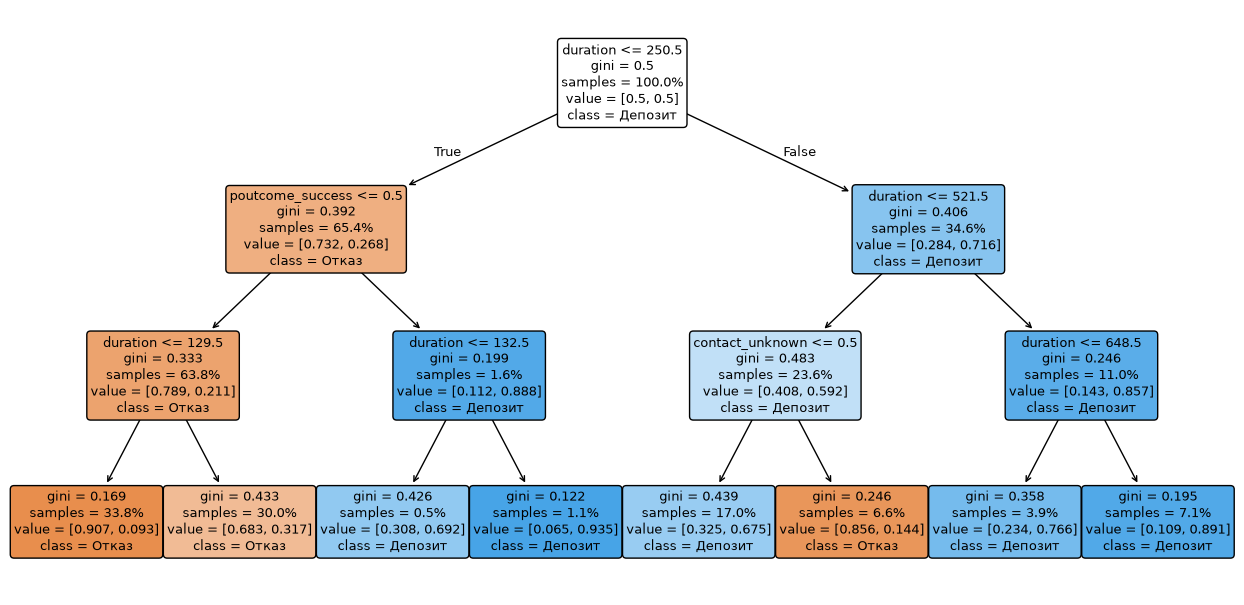

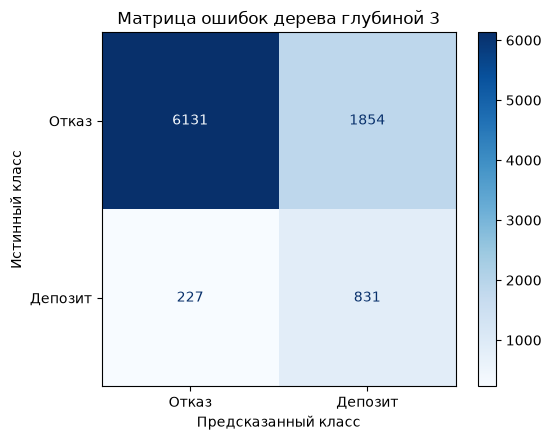

Отчет по дереву глубиной 3:
              precision    recall  f1-score   support

       Отказ       0.96      0.77      0.85      7985
     Депозит       0.31      0.79      0.44      1058

    accuracy                           0.77      9043
   macro avg       0.64      0.78      0.65      9043
weighted avg       0.89      0.77      0.81      9043



In [2]:
base_pipe = fitted_pipes["Дерево гл. 3, Джини"]
feat_names = get_feature_names(base_pipe.named_steps["pre"])
fig_tree = plot_tree(base_pipe.named_steps["clf"], feature_names=feat_names)
plt.show()

fig_cm = plot_confusion(base_pipe, X_test, y_test)
plt.title("Матрица ошибок дерева глубиной 3")
plt.show()

print("Отчет по дереву глубиной 3:")
print(classification_report(y_test, base_pipe.predict(X_test), target_names=["Отказ", "Депозит"]))